# Football Scout Agent: graph, GDS and link prediction

Owner: C. A tour of the Neo4j transfer graph, the Graph Data Science results written back to it, and the
link-prediction model, with its baseline.

**Run it.** Start Neo4j with the graph loaded (`make docker-run`, or `make seed` on a local Neo4j with the GDS plugin),
put the connection in `.env` (`NEO4J_URI`, `NEO4J_USER`, `NEO4J_PASSWORD`), run `python -m ml.train_link_prediction`
once to write the predictions, then *Run all*. Section 7 reads the DuckDB file (`make data`) and takes about a minute.

**Three levels of truth, never mixed:** facts (Transfermarkt), computed values (PageRank, communities, embeddings:
derived from the facts) and predictions (`PREDICTED_LINK`, `PREDICTED_MOVE`: hypotheses of a model).

In [1]:
import sys
from dataclasses import replace
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "app").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd

from app.config import get_settings
from app.database.neo4j import Neo4jClient
from app.services.gds import GDS_TIMEOUT_S, GdsService

settings = get_settings()  # reads .env (or the environment): NEO4J_URI, NEO4J_USER, NEO4J_PASSWORD
client = Neo4jClient(
    settings.neo4j_uri, (settings.neo4j_user, settings.neo4j_password), settings.neo4j_database, GDS_TIMEOUT_S
)
gds = GdsService(client)
print(f"Neo4j at {settings.neo4j_uri}: reachable = {client.ping()}")

# Chart style: one hue for a single series, neutral ink for text and axes, light grid.
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK_2, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
plt.rcParams.update({
    "figure.dpi": 90, "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2, "text.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.spines.top": False,
    "axes.spines.right": False, "axes.axisbelow": True, "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
})
pd.set_option("display.max_colwidth", 80)


def show(frame, digits=3):
    # Print a table without its index (light notebook outputs).
    print(frame.round(digits).to_string(index=False))

Neo4j at bolt://localhost:7687: reachable = True


## 1. What is in the graph

Nodes and relationships per type. Facts come from Transfermarkt (ingestion of role A); `SENDS_TO` and `PLAYED_WITH`
are aggregated from them; `PREDICTED_*` are the model's hypotheses (section 8).

In [2]:
nodes = pd.DataFrame(client.read(
    "MATCH (n) UNWIND labels(n) AS label RETURN label, count(*) AS nodes ORDER BY nodes DESC LIMIT 20"
))
relationships = pd.DataFrame(client.read(
    "MATCH ()-[r]->() RETURN type(r) AS type, count(*) AS relationships ORDER BY relationships DESC LIMIT 30"
))
show(nodes)
show(relationships)

      label  nodes
  Valuation 250988
   Transfer  34744
     Player  17856
       Club   2232
    Country    166
Competition      7
          type  relationships
   PLAYED_WITH         359707
 HAS_VALUATION         250988
PREDICTED_MOVE          41961
          MADE          34744
          FROM          34744
            TO          34744
      SENDS_TO          22713
     PLAYS_FOR          17850
    CITIZEN_OF          17718
      PLAYS_IN           1468
PREDICTED_LINK           1115
    IN_COUNTRY              7


## 2. Recompute the GDS scores

`refresh` projects two in-memory graphs (`clubs`: `Club` + `SENDS_TO` weighted by transfer count; `teammates`:
`Player` + undirected `PLAYED_WITH` weighted by matches), writes PageRank, Louvain communities and FastRP embeddings
back to the nodes, and drops the projections. Same call as `POST /api/admin/gds/refresh`. The first run after a
Neo4j start pays the GDS warm-up (about 12 s on the full graph); the next ones take about 2 s.

In [3]:
report = gds.refresh()
report

GdsRefreshReport(projections=['clubs', 'teammates'], algorithms=['pageRank', 'louvain', 'fastRP'], duration_s=1.776)

## 3. Hubs of the transfer market (weighted PageRank)

PageRank flows along `SENDS_TO` from seller to buyer: a high score marks a club that **receives** players from
other central clubs. It counts *who* the partners are, not only how many (that would be the degree).

 club_id                       name  score
     252                  Genoa CFC  13.96
     276              Hellas Verona  12.76
      46                Inter Milan  12.03
     430             ACF Fiorentina  11.39
     800                Atalanta BC  11.09
      12 Associazione Sportiva Roma  11.02
     703          Nottingham Forest  10.97
     294                 SL Benfica  10.87
     410             Udinese Calcio  10.66
     336                Sporting CP  10.55


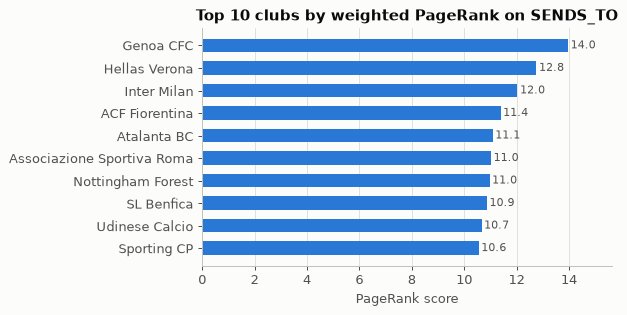

In [4]:
hubs = pd.DataFrame([hub.model_dump() for hub in gds.hubs(10)])
show(hubs, 2)

fig, ax = plt.subplots(figsize=(7, 3.6))
ordered = hubs.iloc[::-1]
ax.barh(ordered["name"], ordered["score"], color=BLUE, height=0.6)
for y, score in enumerate(ordered["score"]):
    ax.text(score + 0.1, y, f"{score:.1f}", va="center", color=INK_2, fontsize=9)
ax.set_title("Top 10 clubs by weighted PageRank on SENDS_TO")
ax.set_xlabel("PageRank score")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, ordered["score"].max() * 1.12)
plt.tight_layout()
plt.show()

## 4. Transfer communities (Louvain)

Louvain groups clubs so that most of the transfer weight stays inside groups (it maximises modularity). Clubs are
listed by decreasing PageRank.

In [5]:
communities = gds.communities(min_size=2)
table = pd.DataFrame([
    {"community_id": c.community_id, "size": c.size, "main clubs": ", ".join(c.clubs[:5])} for c in communities[:8]
])
print(f"{len(communities)} communities with at least 2 clubs")
show(table)

7 communities with at least 2 clubs
 community_id  size                                                                                  main clubs
           56   495                               SL Benfica, Sporting CP, FC Porto, CD Santa Clara, Rio Ave FC
           49   335                          Genoa CFC, Hellas Verona, Inter Milan, ACF Fiorentina, Atalanta BC
          149   301                           Olympique Lyon, Stade Rennais FC, AS Monaco, LOSC Lille, OGC Nice
           45   278   Feyenoord Rotterdam, Fortuna Sittardia Combinatie, Ajax Amsterdam, FC Utrecht, AZ Alkmaar
          125   259 Nottingham Forest, Chelsea FC, Wolverhampton Wanderers, Brighton & Hove Albion, Aston Villa
           40   243   Eintracht Frankfurt, TSG 1899 Hoffenheim, VfB Stuttgart, VfL Wolfsburg, 1.FC Union Berlin
          219   243                  Manchester City, Atlético de Madrid, Watford FC, Sevilla FC, Villarreal CF


## 5. A sub-network of clubs

The 8 most central clubs of the three largest communities and the `SENDS_TO` relationships between them (at least
2 transfers). Node size follows PageRank, colour the community, line width the number of transfers.

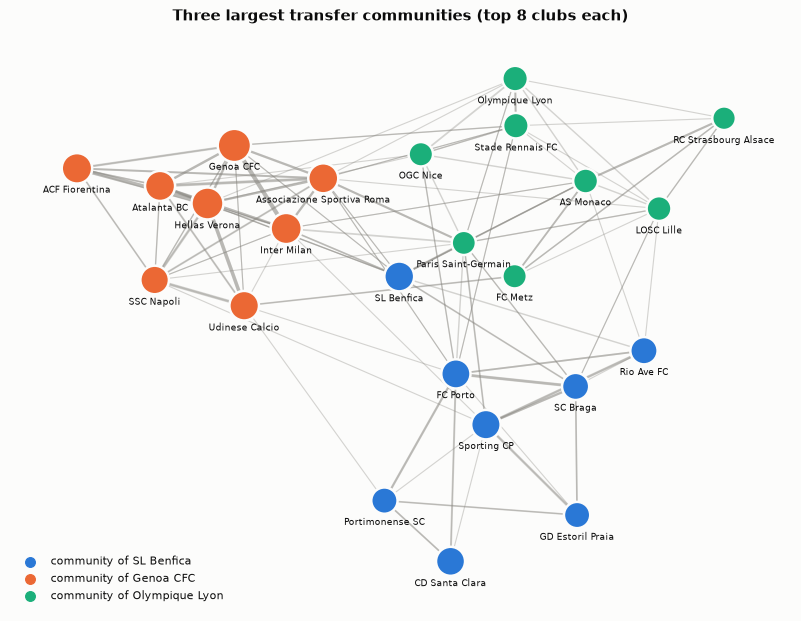

In [6]:
top3 = [c.community_id for c in communities[:3]]
members = pd.DataFrame(client.read(
    """
    MATCH (c:Club) WHERE c.community_id IN $ids
    WITH c ORDER BY c.pagerank DESC
    WITH c.community_id AS community, collect(c)[..8] AS clubs
    UNWIND clubs AS c
    RETURN community, c.club_id AS club_id, c.name AS name, c.pagerank AS pagerank
    LIMIT 100
    """,
    {"ids": top3},
))
links = pd.DataFrame(client.read(
    """
    MATCH (a:Club)-[s:SENDS_TO]->(b:Club)
    WHERE a.club_id IN $ids AND b.club_id IN $ids AND s.count >= 2
    RETURN a.club_id AS src, b.club_id AS dst, s.count AS count
    LIMIT 2000
    """,
    {"ids": members["club_id"].tolist()},
))
graph = nx.DiGraph()
for row in members.itertuples():
    graph.add_node(row.club_id, name=row.name, community=row.community, pagerank=row.pagerank)
graph.add_weighted_edges_from(links.itertuples(index=False, name=None), weight="count")

colours = dict(zip(top3, [BLUE, ORANGE, AQUA]))
position = nx.spring_layout(graph.to_undirected(), weight="count", seed=42, k=0.9)
fig, ax = plt.subplots(figsize=(9, 7))
ax.grid(False)
ax.axis("off")
nx.draw_networkx_edges(
    graph, position, ax=ax, edge_color=MUTED, alpha=0.35, arrows=False,
    width=[0.4 + 0.25 * graph.edges[edge]["count"] for edge in graph.edges],
)
nx.draw_networkx_nodes(
    graph, position, ax=ax, edgecolors=SURFACE, linewidths=2,
    node_color=[colours[graph.nodes[node]["community"]] for node in graph.nodes],
    node_size=[80 + 45 * graph.nodes[node]["pagerank"] for node in graph.nodes],
)
nx.draw_networkx_labels(
    graph, {node: (x, y - 0.075) for node, (x, y) in position.items()},
    labels={node: graph.nodes[node]["name"] for node in graph.nodes}, font_size=7, font_color=INK, ax=ax,
)
for community in top3:
    leader = members[members["community"] == community].iloc[0]["name"]
    ax.scatter([], [], color=colours[community], s=60, label=f"community of {leader}")
ax.legend(loc="lower left", frameon=False, fontsize=9)
ax.set_title("Three largest transfer communities (top 8 clubs each)")
plt.tight_layout()
plt.show()

## 6. Similar players (FastRP on the teammate graph)

Cosine similarity of FastRP embeddings computed on `PLAYED_WITH`: two players are close when their teammate
neighbourhoods overlap. It is **not** a similarity of position or style: combine it with the position filter of
`GET /api/players/search` for a real "player like X" question.

In [7]:
found = client.read("MATCH (p:Player {name: $name}) RETURN p.player_id AS player_id LIMIT 1", {"name": "Bradley Barcola"})
player_id = found[0]["player_id"] if found else client.read(
    "MATCH (p:Player) WHERE p.market_value_eur IS NOT NULL "
    "RETURN p.player_id AS player_id ORDER BY p.market_value_eur DESC LIMIT 1"
)[0]["player_id"]
similar = pd.DataFrame([player.model_dump() for player in gds.similar_players(player_id, k=5)])
print("Reference player id:", player_id)
show(similar)

Reference player id: 708265
 player_id           name  similarity
    903693   Senny Mayulu       0.960
    872171  Lucas Beraldo       0.959
    318470 Matvey Safonov       0.958
   1185888  Ibrahim Mbaye       0.957
   1041614   Renato Marin       0.953


## 7. Link prediction: model vs baseline

Will two clubs that never traded trade within the next two seasons? Temporal protocol (details in
`docs/ml_report.md`): features on the 4 seasons before each cut-off; model chosen on a validation window
(fit on 2015-2018, validated on the new pairs of 2021-2022); evaluated **once** on every open pair at the end of
2022, labelled by the new pairs of 2023-2024 (about 3.6 % positives). The baseline ranks pairs by their number of
common neighbours.

In [8]:
from sklearn.metrics import precision_recall_curve

from ml.dataset import FEATURES, TEST_SPLIT, TRAIN_SPLIT, build_full_split, build_split, load_universe
from ml.train_link_prediction import FEATURE_WINDOW, VALIDATION_SPLIT, compare, make_models

universe = replace(load_universe(), feature_window=FEATURE_WINDOW)
splits = {
    "fit": build_split(universe, VALIDATION_SPLIT),
    "validation": build_full_split(universe, TRAIN_SPLIT),
    "train": build_split(universe, TRAIN_SPLIT),
    "test_full": build_full_split(universe, TEST_SPLIT),
}
results, chosen = compare(splits)
test = splits["test_full"]
print(f"test set: {len(test):,} open pairs, {int(test['label'].sum()):,} new links ({test['label'].mean():.1%})")
print("chosen on validation:", chosen)
metrics = pd.DataFrame(results).T.rename(index={
    "common_neighbours_baseline": "common neighbours (baseline)",
    "logistic_regression": "logistic regression",
    "gradient_boosting": "gradient boosting",
})
print(metrics.round(3).fillna("-").to_string())

test set: 43,442 open pairs, 1,576 new links (3.6%)
chosen on validation: logistic_regression
                             val_auc_pr  auc_pr roc_auc precision_at_50 precision_at_100
common neighbours (baseline)      0.109   0.126   0.794            0.16             0.26
logistic regression               0.153   0.166   0.823            0.34             0.29
gradient boosting                 0.132   0.146    0.81            0.26             0.31
random                                -   0.036       -               -                -


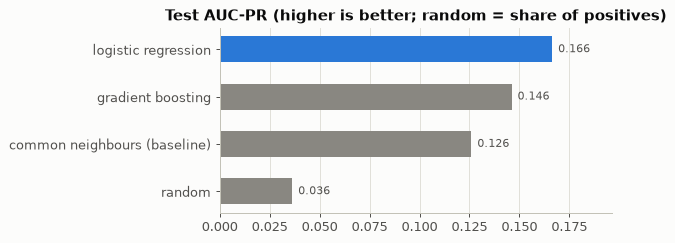

In [9]:
names = ["random", "common neighbours (baseline)", "gradient boosting", "logistic regression"]
values = [metrics.loc[name, "auc_pr"] for name in names]
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.barh(names, values, color=[MUTED, MUTED, MUTED, BLUE], height=0.55)
for y, value in enumerate(values):
    ax.text(value + 0.003, y, f"{value:.3f}", va="center", color=INK_2, fontsize=9)
ax.set_title("Test AUC-PR (higher is better; random = share of positives)")
ax.set_xlim(0, max(values) * 1.18)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

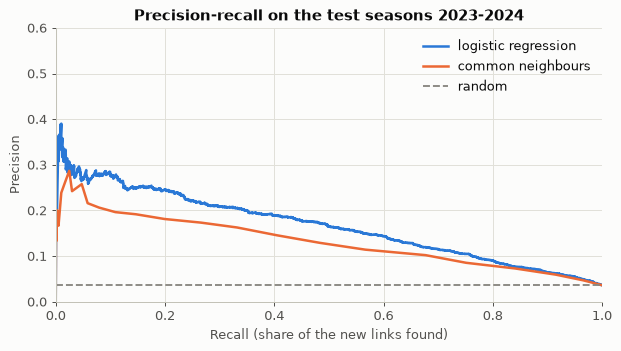

In [10]:
model = make_models()["logistic_regression"].fit(splits["train"][FEATURES], splits["train"]["label"])
curves = {
    "logistic regression": (model.predict_proba(test[FEATURES])[:, 1], BLUE),
    "common neighbours": (test["common_neighbours"], ORANGE),
}
fig, ax = plt.subplots(figsize=(7, 4))
for label, (scores, colour) in curves.items():
    precision, recall, _ = precision_recall_curve(test["label"], scores)
    ax.plot(recall, precision, color=colour, linewidth=2, label=label)
ax.axhline(test["label"].mean(), color=MUTED, linestyle="--", linewidth=1.5, label="random")
ax.set_xlabel("Recall (share of the new links found)")
ax.set_ylabel("Precision")
ax.set_title("Precision-recall on the test seasons 2023-2024")
ax.set_xlim(0, 1)
ax.set_ylim(0, 0.6)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

Honest reading: the task is hard, most top-ranked pairs do not trade within two seasons. Still, among its 50 most
probable new pairs the model finds 17 real new links, twice the baseline (8) and about 9 times chance (1.8); at 100
the gap narrows (29 vs 26), and gradient boosting does slightly better there (31) although it is worse overall.
FastRP club embeddings were also tried as features (cosine, Hadamard product, directed) and did not help:
`python -m ml.fastrp_experiment`.

## 8. Predictions stored in the graph (hypotheses, never facts)

`PREDICTED_LINK`: the 5 most probable new destinations of each club. `PREDICTED_MOVE`: the 3 best links of a player's
current club. The probability is the one of the **pair of clubs** within **2 seasons**, corrected for the 1-in-6
training sample: it says where players of this club tend to go, not that this player will move.

In [11]:
top_links = pd.DataFrame(client.read(
    """
    MATCH (a:Club)-[r:PREDICTED_LINK]->(b:Club)
    RETURN a.name AS seller, b.name AS buyer, r.prob AS probability, r.horizon_seasons AS horizon_seasons,
           r.model_version AS model_version
    ORDER BY probability DESC, seller LIMIT 10
    """
))
show(top_links, 2)
moves = pd.DataFrame([move.model_dump() for move in gds.predicted_moves(player_id)])
show(moves, 2)

                 seller                   buyer  probability  horizon_seasons                   model_version
              Como 1907           Hellas Verona         0.61                2 lp-logistic_regression-20261020
          Hellas Verona               Como 1907         0.61                2 lp-logistic_regression-20261020
       Stade Rennais FC                 RC Lens         0.58                2 lp-logistic_regression-20261020
Wolverhampton Wanderers              Burnley FC         0.57                2 lp-logistic_regression-20261020
      Nottingham Forest         AFC Bournemouth         0.57                2 lp-logistic_regression-20261020
        AFC Bournemouth  Brighton & Hove Albion         0.56                2 lp-logistic_regression-20261020
 Brighton & Hove Albion         AFC Bournemouth         0.56                2 lp-logistic_regression-20261020
    TSG 1899 Hoffenheim           VfL Wolfsburg         0.56                2 lp-logistic_regression-20261020
          

In [12]:
client.close()